In [1]:
from rdkit import Chem


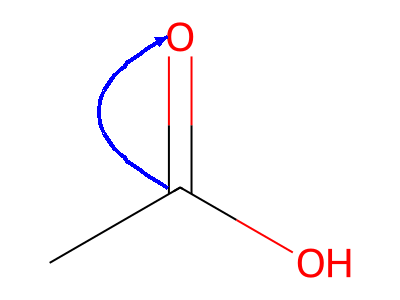

In [4]:
from rdkit.Chem import AllChem, Draw
from PIL import Image, ImageDraw
import numpy as np

def ensure_2d(mol):
    if mol.GetNumConformers() == 0:
        AllChem.Compute2DCoords(mol)
    return mol.GetConformer()

def atom_pixel_positions(mol, size=(400, 300), pad_frac=0.12):
    """
    Map atom 2D coordinates to pixel coordinates for an image of given size.
    Returns list of (x_px, y_px) for each atom.
    """
    w, h = size
    conf = ensure_2d(mol)
    coords = np.array([[conf.GetAtomPosition(i).x, conf.GetAtomPosition(i).y] for i in range(mol.GetNumAtoms())])
    minxy = coords.min(axis=0)
    maxxy = coords.max(axis=0)
    # prevent zero-size
    span = np.maximum(maxxy - minxy, 1e-6)
    pad_px = pad_frac * min(w, h)
    scale = min((w - 2 * pad_px) / span[0], (h - 2 * pad_px) / span[1])
    # map x -> [pad_px, w-pad_px], y -> [pad_px, h-pad_px] but flip y for image coords
    x_px = (coords[:, 0] - minxy[0]) * scale + pad_px
    y_px = (coords[:, 1] - minxy[1]) * scale + pad_px
    y_px = h - y_px  # flip to image coordinate system
    return [(float(x), float(y)) for x, y in zip(x_px, y_px)]

def _quad_bezier_points(p0, p1, p2, n=32):
    t = np.linspace(0, 1, n)
    pts = (1 - t)[:, None]**2 * p0 + 2 * (1 - t)[:, None] * t[:, None] * p1 + t[:, None]**2 * p2
    return [tuple(pt) for pt in pts]

def _draw_arrowhead(draw, tip, direction, size=12, color=(255,0,0)):
    """
    Draw a triangular arrowhead. `direction` should be a unit vector pointing to the tip.
    """
    # base center
    perp = np.array([-direction[1], direction[0]])
    base_center = np.array(tip) - np.array(direction) * size
    left = base_center + perp * (size * 0.45)
    right = base_center - perp * (size * 0.45)
    draw.polygon([tuple(tip), tuple(left), tuple(right)], fill=color)

def draw_curved_arrow_on_image(img, start_px, end_px, curvature=0.25, color=(255,0,0), width=4):
    """
    Draw a curved quadratic Bezier arrow from start_px to end_px on a PIL Image.
    curvature: positive -> control point to left of direction (as defined by perpendicular)
    """
    draw = ImageDraw.Draw(img)
    p0 = np.array(start_px, dtype=float)
    p2 = np.array(end_px, dtype=float)
    mid = (p0 + p2) / 2.0
    vec = p2 - p0
    dist = np.linalg.norm(vec)
    if dist < 1e-6:
        return
    perp = np.array([-vec[1], vec[0]])
    perp = perp / (np.linalg.norm(perp) + 1e-12)
    ctrl = mid + perp * (dist * curvature)
    pts = _quad_bezier_points(p0, ctrl, p2, n=48)
    draw.line(pts, fill=color, width=width)
    # compute arrowhead direction (derivative at t=1: 2*(e - ctrl))
    dir_vec = p2 - ctrl
    dir_vec = dir_vec / (np.linalg.norm(dir_vec) + 1e-12)
    arrow_size = max(6, int(dist * 0.08))
    _draw_arrowhead(draw, tuple(p2), dir_vec, size=arrow_size, color=color)

def draw_mol_with_arrows(mol, arrows, size=(400,300), curvature=0.25, arrow_color=(255,0,0), arrow_width=4, bg_color=(255,255,255)):
    """
    Draw molecule using RDKit and overlay curved arrows.
    - mol: RDKit Mol
    - arrows: list of (start_atom_idx, end_atom_idx) or dicts with keys ('start','end','curvature','color','width')
    Returns a PIL.Image.
    """
    # ensure 2D coords exist
    ensure_2d(mol)
    # base image from RDKit
    pil_img = Draw.MolToImage(mol, size=size, kekulize=True, wedgeBonds=True, bg=bg_color)
    atom_pos = atom_pixel_positions(mol, size=size)
    # normalize arrows input
    normal_arrows = []
    for a in arrows:
        if isinstance(a, (list, tuple)) and len(a) >= 2:
            s, e = a[0], a[1]
            kw = {}
            if len(a) > 2 and isinstance(a[2], dict):
                kw = a[2]
            normal_arrows.append({'start': s, 'end': e, 'curvature': kw.get('curvature', curvature),
                                   'color': kw.get('color', arrow_color), 'width': kw.get('width', arrow_width)})
        elif isinstance(a, dict):
            normal_arrows.append({'start': a['start'], 'end': a['end'],
                                   'curvature': a.get('curvature', curvature),
                                   'color': a.get('color', arrow_color),
                                   'width': a.get('width', arrow_width)})
    # draw each arrow
    for a in normal_arrows:
        s_idx, e_idx = a['start'], a['end']
        if s_idx < 0 or e_idx < 0 or s_idx >= len(atom_pos) or e_idx >= len(atom_pos):
            continue
        start_px = atom_pos[s_idx]
        end_px = atom_pos[e_idx]
        draw_curved_arrow_on_image(pil_img, start_px, end_px, curvature=a['curvature'], color=a['color'], width=a['width'])
    return pil_img

# Example usage:
mol = Chem.MolFromSmiles("CC(=O)O")  # make sure Chem is available from previous cell
# img = draw_mol_with_arrows(mol, arrows=[(0, 2), {'start': 1, 'end': 2, 'curvature': -0.3, 'color': (0,0,255)}])
img = draw_mol_with_arrows(mol, arrows=[{'start': 1, 'end': 2, 'curvature': -0.9, 'color': (0,0,255)}])
display(img)  # in a Jupyter cell this will show the PIL image

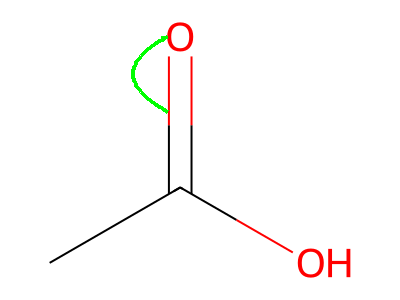

In [7]:
def draw_mol_with_arrows(mol, arrows, size=(400,300), curvature=0.25, arrow_color=(255,0,0), arrow_width=4, bg_color=(255,255,255)):
    """
    Draw molecule using RDKit and overlay curved arrows.
    - mol: RDKit Mol
    - arrows: list of (start_atom_idx, end_atom_idx), (bond_idx, end_atom_idx), or dicts with keys ('start','end','curvature','color','width')
      where 'start' can be an atom index or ('bond', bond_idx) tuple
    Returns a PIL.Image.
    """
    # ensure 2D coords exist
    ensure_2d(mol)
    # base image from RDKit
    pil_img = Draw.MolToImage(mol, size=size, kekulize=True, wedgeBonds=True, bg=bg_color)
    atom_pos = atom_pixel_positions(mol, size=size)
    
    def get_start_position(start_spec):
        """Helper to get pixel position from atom index or bond index."""
        if isinstance(start_spec, int):
            return atom_pos[start_spec]
        elif isinstance(start_spec, tuple) and start_spec[0] == 'bond':
            bond_idx = start_spec[1]
            bond = mol.GetBondWithIdx(bond_idx)
            begin_pos = np.array(atom_pos[bond.GetBeginAtomIdx()])
            end_pos = np.array(atom_pos[bond.GetEndAtomIdx()])
            return tuple((begin_pos + end_pos) / 2.0)
        else:
            return atom_pos[start_spec]
    
    # normalize arrows input
    normal_arrows = []
    for a in arrows:
        if isinstance(a, (list, tuple)) and len(a) >= 2:
            s, e = a[0], a[1]
            kw = {}
            if len(a) > 2 and isinstance(a[2], dict):
                kw = a[2]
            normal_arrows.append({'start': s, 'end': e, 'curvature': kw.get('curvature', curvature),
                                   'color': kw.get('color', arrow_color), 'width': kw.get('width', arrow_width)})
        elif isinstance(a, dict):
            normal_arrows.append({'start': a['start'], 'end': a['end'],
                                   'curvature': a.get('curvature', curvature),
                                   'color': a.get('color', arrow_color),
                                   'width': a.get('width', arrow_width)})
    # draw each arrow
    for a in normal_arrows:
        s_spec, e_idx = a['start'], a['end']
        if isinstance(e_idx, int) and (e_idx < 0 or e_idx >= len(atom_pos)):
            continue
        start_px = get_start_position(s_spec)
        end_px = atom_pos[e_idx]
        draw_curved_arrow_on_image(pil_img, start_px, end_px, curvature=a['curvature'], color=a['color'], width=a['width'])
    return pil_img

# Example: arrow starting from bond 0, pointing to atom 2
img = draw_mol_with_arrows(mol, arrows=[{'start': ('bond', 1), 'end': 2, 'curvature': -0.9, 'color': (0,255,0)}])
display(img)